## 4. Model Evaluation 

This section is devoted to tuning and evaluating the model for the whole corpus and then filtering based on topics to allow for further topic modelling to get more detailed break downs layer by layer.\
\
First, tokens will be grouped into phrases. Some phrases are not just one word and have a different meaning with other words e.g. 'general election' is different to 'general' and 'election' on their own. To capture this meaning, using bigrams and trigrams (algorithms to gather together frequently paired words) to increase accuracy in the model.

In [3]:
# import relevant libraries
# accessing and saving dataframes
import pandas as pd
import pyarrow.parquet as pq
import pyarrow as pa
import os

# importing gensim which is used for LDA and feature extraction
import gensim
from gensim import corpora

# bigramgs and trigrams
from gensim.models import Phrases
from gensim.models.phrases import Phraser

# for visualising coherence
import matplotlib.pyplot as plt
from gensim.models import CoherenceModel
from gensim.models import LdaModel

# for creating tfidf and bow corpus
from gensim.models.tfidfmodel import TfidfModel

# silhouette coefficient and calinski-harabasz index
from sklearn.metrics import silhouette_score, calinski_harabasz_score

# visuals to show inter-topic distances, top terms per topic and relevance and topic proportions
import pyLDAvis.gensim_models

In [4]:
# import in the data from parquet files and csv
petitions_metadata_df = pd.read_csv('data\petitions_metadata.csv')

petitions_table = pq.read_table('data\petitions_processed_data.parquet')
countries_table = pq.read_table('data\petitions_country_data.parquet')
regions_table = pq.read_table('data\petitions_region_data.parquet')
constituencies_table = pq.read_table('data\petitions_constituency_data.parquet')

petitions_df = petitions_table.to_pandas()
countries_df = countries_table.to_pandas()
regions_df = regions_table.to_pandas()
constituencies_df = constituencies_table.to_pandas()

petitions_df.shape

<>:2: DeprecationWarning: invalid escape sequence \p
<>:4: DeprecationWarning: invalid escape sequence \p
<>:5: DeprecationWarning: invalid escape sequence \p
<>:6: DeprecationWarning: invalid escape sequence \p
<>:7: DeprecationWarning: invalid escape sequence \p
<>:2: DeprecationWarning: invalid escape sequence \p
<>:4: DeprecationWarning: invalid escape sequence \p
<>:5: DeprecationWarning: invalid escape sequence \p
<>:6: DeprecationWarning: invalid escape sequence \p
<>:7: DeprecationWarning: invalid escape sequence \p
C:\Users\morriseb\AppData\Local\Temp\ipykernel_29356\3575195738.py:2: DeprecationWarning: invalid escape sequence \p
  petitions_metadata_df = pd.read_csv('data\petitions_metadata.csv')
C:\Users\morriseb\AppData\Local\Temp\ipykernel_29356\3575195738.py:4: DeprecationWarning: invalid escape sequence \p
  petitions_table = pq.read_table('data\petitions_processed_data.parquet')
C:\Users\morriseb\AppData\Local\Temp\ipykernel_29356\3575195738.py:5: DeprecationWarning: in

(43473, 8)

In [5]:
petitions_sample = petitions_df[:1000]

petitions_con_1 = petitions_df[petitions_df['parliament'] == 1]
petitions_con_2 = petitions_df[petitions_df['parliament'] == 2]
petitions_con_3 = petitions_df[petitions_df['parliament'] == 3]
petitions_con_4 = petitions_df[petitions_df['parliament'] == 4]

In [6]:
processed_sample = petitions_sample['clean_text'].values

processed_con_1 = petitions_con_1['clean_text'].values
processed_con_2 = petitions_con_2['clean_text'].values
processed_con_3 = petitions_con_3['clean_text'].values
processed_con_4 = petitions_con_4['clean_text'].values

Creating a function which builds phrases which will then be tuned later using threshold and min_count.

In [7]:
def build_phrases(processed_text, threshold, min_count):
    """
    function to collect tokens into multi word phrases
    :param processed_text: array of processed text tokens to be turned into phrases
    :param threshold: integer, threshold calculated such that if reached tokens are combined into phrase
    :param min_count: integer, smallest number of occasions that 2 or more tokens are seen together to allow grouping
    :output: bigrams and trigrams
    """
    # collecting individual words into common pairings and in some cases triples
    bigram = Phrases(processed_text, min_count=min_count, threshold=threshold)
    trigram = Phrases(bigram[processed_text], threshold)

    # converts phrases models into objects for faster transformation
    bigram_mod = Phraser(bigram)
    trigram_mod = Phraser(trigram)

    # applying the bigram and trigrams to the docs
    docs_bigrams = [bigram_mod[doc] for doc in processed_text]
    docs_trigrams = [trigram_mod[bigram_mod[doc]] for doc in processed_text]

    return docs_bigrams, docs_trigrams

Creating function to extract vocabulary and convert text to vectors using Term frequency-inverse document frequency (TF-IDF) and Bag of Words (BoW). BoW is a model of unordered text which is then used as an input into TF-IDF. TF-IDF looks at the term frequency of each word in a document and compares it to the relative frequency of that term in the whole collection of documents, giving a higher score to terms that appear lots in one document and not much elsewhere. As a result, words like 'with' or 'and' would get lower scores as they appear everywhere but topic specific terms would receive higher scores, which will tell us more about the kinds of documents we're looking at.\
\
I have used the below code as reference:\
https://github.com/LaurentVeyssier/Topic-Modeling-and-Document-Categorization-using-Latent-Dirichlet-Allocation/blob/main/Latent_dirichlet_allocation.ipynb

In [8]:
def prepare_corpus(docs_trigrams):
    """
    function to create dictionary and corpus for LDA model using trigrams
    :param docs_trigrams: trigrams created from the build_phrases function by inputting the processed text
    :output: dictionary and corpus_tfidf outputted with dictionary constructed for trigrams with extremes filtered and corpus constructed using BoW and TF-IDF
    """
    # creating a bag of words corpus for future use and for tfidf
    dictionary = corpora.Dictionary(docs_trigrams)
    dictionary.filter_extremes(no_below=15, no_above=0.1, keep_n=100000)

    # creating tf idf corpus from BoW
    bow_corpus = [dictionary.doc2bow(doc) for doc in docs_trigrams]

    # Initialize the model
    tfidf = TfidfModel(bow_corpus)

    # apply transformation
    corpus_tfidf = tfidf[bow_corpus]

    return dictionary, corpus_tfidf

# dictionary, corpus_tfidf = prepare_corpus(docs_trigrams)

To choose how many topics to extract, using a Cv coherence model to check the coherence of each topic and mark it. Cv computes context vectors for words and measures similarity between word pairs and a higher Cv score indicates better coherence, aiming for a score of around 0.6.

In [9]:
def evaluate_cv_coherence(model, dictionary, docs_trigrams):
    """ 
    Takes model as input and creates Cv coherence model
    :param model: LDA model
    :param dictionary: dictionary of phrases from inputted model
    :param docs_trigrams: trigrams formed from inputted model
    :output: Cv coherence score (decimal)
    """
    # instantiating model and getting coherence score
    coherence_model = CoherenceModel(model=model,
                                     texts=docs_trigrams,
                                     dictionary=dictionary,
                                     coherence='c_v')

    coherence = coherence_model.get_coherence()
    return coherence

The below tuning is for the parameters: passes, iterations, alpha, eta and chunksize, which will be used for each model batched into parliament and year. As some parliaments are significantly longer than others, results may be variable so will also batch by year to see if coherence increases for the more consistent and short time periods. The top 10 models are saved to their own folder with a parameters text file. If another model has higher performance than one of the models in this file, it is also saved. E.g. the first ten models are saved and then any other higher performing model is also saved.

In [19]:
import os

scores = []

params = {
    'threshold': [100, 150, 200],
    'min_count': [5, 10],
    'passes': [100, 500],
    'iterations': [500, 1000],
    'chunksize': [500, 1000]   
}

count = 0
param_names = list(params.keys())


# Loop through combinations
for threshold in params['threshold']:
    for min_count in params['min_count']:
        for passes in params['passes']:
            for iterations in params['iterations']:
                for chunksize in params['chunksize']:
                    count+=1
                    docs_bigrams, docs_trigrams = build_phrases(
                        processed_sample,
                        threshold=threshold,
                        min_count=min_count
                    )

                    # Prepare corpus
                    dictionary, corpus_tfidf = prepare_corpus(docs_trigrams)

                    model = gensim.models.LdaMulticore(corpus=corpus_tfidf, 
                                                num_topics = 14, 
                                                id2word = dictionary, 
                                                passes = passes,
                                                iterations = iterations,
                                                chunksize=chunksize,
                                                alpha=0.01,
                                                eta=0.01, 
                                                random_state= 42)
                    
                    # find coherence scores
                    cv_score = evaluate_cv_coherence(model, dictionary, docs_trigrams)

                    score = {
                        'cv_score': cv_score,
                        'threshold': threshold,
                        'min_count': min_count,
                        'passes': passes,
                        'iterations': iterations,
                        'chunksize': chunksize
                    }

                    scores.append(score)
                    top_n = 10

                    scores_sorted = sorted(scores, key=lambda x: x['cv_score'], reverse=True)

                    if len(scores_sorted) <= top_n or score['cv_score'] >= scores_sorted[top_n - 1]['cv_score']:
                        model_dir = f"models/model_{count}"
                        os.makedirs(model_dir, exist_ok=True)
                        dictionary.save(f"{model_dir}/dictionary.dict")
                        corpora.MmCorpus.serialize(f"{model_dir}/corpus.mm", corpus_tfidf)
                        model.save(f"{model_dir}/model.gensim")
                        with open(f"{model_dir}/params.txt", "w") as file:
                            for key in param_names:
                                file.write(f"{key}: {score[key]}\n")
                            file.write(f"cv_score: {score['cv_score']}")
                        print(f'Result: model_{count}, {cv_score}')

Result: model_1, 0.6489054569755374
Result: model_2, 0.6489054569755374
Result: model_3, 0.6489054569755374
Result: model_4, 0.6489054569755374
Result: model_5, 0.6489054569755374
Result: model_6, 0.6489054569755374
Result: model_7, 0.6489054569755374
Result: model_8, 0.6489054569755374
Result: model_9, 0.645511472578835
Result: model_10, 0.645511472578835
Result: model_11, 0.645511472578835
Result: model_12, 0.645511472578835
Result: model_17, 0.6560812340113614
Result: model_18, 0.6560812340113614
Result: model_19, 0.6560812340113614
Result: model_20, 0.6560812340113614
Result: model_21, 0.6560812340113614
Result: model_22, 0.6560812340113614
Result: model_23, 0.6560812340113614
Result: model_24, 0.6560812340113614
Result: model_33, 0.6560812340113614
Result: model_34, 0.6560812340113614
Result: model_35, 0.6560812340113614
Result: model_36, 0.6560812340113614
Result: model_37, 0.6560812340113614
Result: model_38, 0.6560812340113614
Result: model_39, 0.6560812340113614
Result: model_

The highest performing model can be seen as model 17 with parameters: threshold=150, min_count=5, passes=100, iterations=500, chunksize=500, alpha=0.01 and eta=0.01 with the only variation being iterations 

## Topic modelling by year
First generating year files

In [10]:
petitions_2015 = petitions_df[petitions_df['created_at'].dt.year == 2015]
petitions_2016 = petitions_df[petitions_df['created_at'].dt.year == 2016]
petitions_2017 = petitions_df[petitions_df['created_at'].dt.year == 2017]
petitions_2018 = petitions_df[petitions_df['created_at'].dt.year == 2018]
petitions_2019 = petitions_df[petitions_df['created_at'].dt.year == 2019]
petitions_2020 = petitions_df[petitions_df['created_at'].dt.year == 2020]
petitions_2021 = petitions_df[petitions_df['created_at'].dt.year == 2021]
petitions_2022 = petitions_df[petitions_df['created_at'].dt.year == 2022]
petitions_2023 = petitions_df[petitions_df['created_at'].dt.year == 2023]
petitions_2024 = petitions_df[petitions_df['created_at'].dt.year == 2024]
petitions_2025 = petitions_df[petitions_df['created_at'].dt.year == 2025]


processed_2015 = petitions_2015['clean_text'].values
processed_2016 = petitions_2016['clean_text'].values
processed_2017 = petitions_2017['clean_text'].values
processed_2018 = petitions_2018['clean_text'].values
processed_2019 = petitions_2019['clean_text'].values
processed_2020 = petitions_2020['clean_text'].values
processed_2021 = petitions_2021['clean_text'].values
processed_2022 = petitions_2022['clean_text'].values
processed_2023 = petitions_2023['clean_text'].values
processed_2024 = petitions_2024['clean_text'].values
processed_2025 = petitions_2025['clean_text'].values

files = [processed_2015, processed_2016, processed_2017, processed_2018, processed_2019, processed_2020, processed_2021, processed_2022, processed_2023, processed_2024, processed_2025]

Setting up functions to be reused

In [ ]:

seed = 42

topic_range = range(10, 23, 3)  # Try topics from 8 to 12

def find_optimal_topic_num(file, topic_range):

    # array to record Cv and UMass scores
    cv_coherence_scores = []

    docs_bigrams, docs_trigrams = build_phrases(file, threshold=150, min_count=5)
    dictionary, corpus_tfidf = prepare_corpus(docs_trigrams)

    for num_topics in topic_range:
        model = gensim.models.LdaMulticore(corpus=corpus_tfidf, 
                                                    num_topics = num_topics, 
                                                    id2word = dictionary, 
                                                    passes = 100,
                                                    iterations = 500,
                                                    chunksize=500,
                                                    alpha=0.01,
                                                    eta=0.01, 
                                                    random_state= seed)
        
        # finding coherence score
        cv_coherence_score = evaluate_cv_coherence(model, dictionary, docs_trigrams)

        # printing result
        print(f"Num Topics: {num_topics}, Cv Coherence Score: {cv_coherence_score:.4f}")

        # adding to array to allow to be plotted
        cv_coherence_scores.append(cv_coherence_score)  

    # Plotting the elbow
    plt.figure(figsize=(10, 5))
    plt.plot(topic_range, cv_coherence_scores, marker='o')
    plt.xlabel('Number of Topics')
    plt.ylabel('Coherence Score (Cv)')
    plt.title('LDA Topic Coherence Scores')
    plt.grid(True)
    plt.show()

In [ ]:
def generate_model(file, year, num_topics):
    docs_bigrams, docs_trigrams = build_phrases(
                                file,
                                threshold=150,
                                min_count=5
                            )

    # Prepare corpus
    dictionary, corpus = prepare_corpus(docs_trigrams)

    model = gensim.models.LdaMulticore(corpus=corpus, 
                                num_topics = num_topics, 
                                id2word = dictionary, 
                                passes = 100,
                                iterations = 500,
                                chunksize=500,
                                alpha=0.01,
                                eta=0.01, 
                                random_state= 42)

    # find coherence scores
    cv_score = evaluate_cv_coherence(model, dictionary, docs_trigrams)
    print(cv_score)

    # saving the dictionary and corpus for use later in modeling
    os.makedirs(f"models/model_{year}/", exist_ok=True)
    dictionary.save(f"models/model_{year}/dictionary.dict")
    corpora.MmCorpus.serialize(f"models/model_{year}/corpus.mm", corpus)
    model.save(f"models/model_{year}/model.gensim")

    return model, dictionary, corpus

## Topics for 2015

In [13]:
find_optimal_topic_num(processed_2015, topic_range)

KeyboardInterrupt: 

In [ ]:
model, dictionary, corpus = generate_model(processed_2015, 2015, 12)

    # top words per topic
for i, topic in model.show_topics(num_topics=12, num_words=10, formatted=False):
    print(f"Topic {i+1}: {[word for word, _ in topic]}")
    
pyLDAvis.enable_notebook()
vis = pyLDAvis.gensim_models.prepare(model, corpus, dictionary)
pyLDAvis.display(vis)

0.5424329874547634
Topic 1: ['disease', 'parking', 'hunting', 'extra', 'caused', 'higher', 'spending', 'payer', 'stand', 'served']
Topic 2: ['insurance', 'prison', 'contract', 'homeless', 'great', 'april', 'matter', 'agree', 'created', 'soldier']
Topic 3: ['bbc', 'speed', 'traffic', 'vital', 'natural', 'town', 'expense', 'old', 'motorway', 'favour']
Topic 4: ['officer', 'council', 'lord', 'causing', 'nurse', 'protected', 'professional', 'registered', 'spend', 'danger']
Topic 5: ['war', 'military', 'foreign', 'isi', 'syria', 'terrorist', 'park', 'father', 'security', 'armed']
Topic 6: ['drug', 'cannabis', 'buy', 'alcohol', 'english', 'billion', 'cancer', 'drive', 'resource', 'address']
Topic 7: ['sex', 'check', 'cyclist', 'idea', 'awareness', 'user', 'religious', 'centre', 'wear', 'customer']
Topic 8: ['refugee', 'charity', 'asylum', 'penalty', 'europe', 'question', 'accept', 'punishment', 'veteran', 'train']
Topic 9: ['confidence', 'wrong', 'welfare', 'carry', 'account', 'david_cameron

Some key topics may be:
- Topic 5: War and the military
- Topic 6: Drugs and alcohol
- Topic 12: EU and immigration
- Topic 3: Transport and BBC*

## Topics for 2016

Num Topics: 10, Cv Coherence Score: 0.5253
Num Topics: 13, Cv Coherence Score: 0.5330
Num Topics: 16, Cv Coherence Score: 0.5209
Num Topics: 19, Cv Coherence Score: 0.5417
Num Topics: 22, Cv Coherence Score: 0.5373


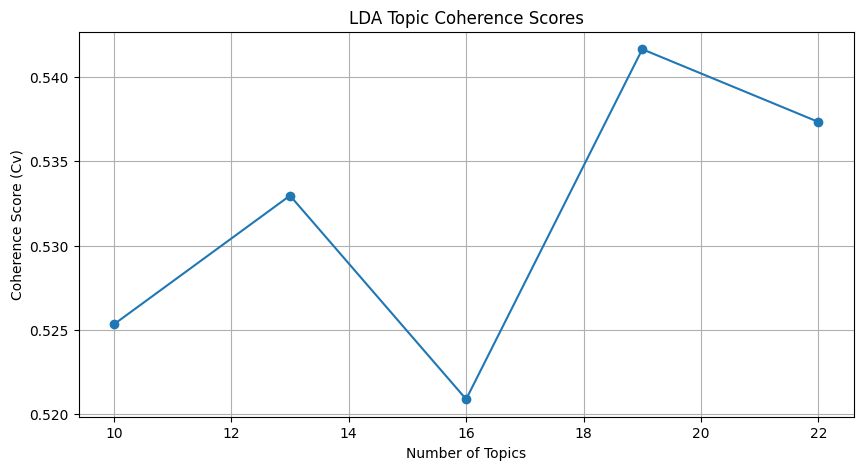

In [29]:
find_optimal_topic_num(processed_2016, topic_range)

In [34]:
model, dictionary, corpus = generate_model(processed_2016, 2016, 13)

    # top words per topic
for i, topic in model.show_topics(num_topics=13, num_words=10, formatted=False):
    print(f"Topic {i+1}: {[word for word, _ in topic]}")
    
pyLDAvis.enable_notebook()
vis = pyLDAvis.gensim_models.prepare(model, corpus, dictionary)
pyLDAvis.display(vis)

0.5344638978175875
Topic 1: ['unit', 'lord', 'rape', 'taxpayer', 'defence', 'rent', 'notice', 'sovereignty', 'advisory', 'contribution']
Topic 2: ['insurance', 'childcare', 'h', 'men', 'partner', 'funded', 'ticket', 'theresa', 'opinion', 'treated']
Topic 3: ['old', 'cannabis', 'gender', 'prescription', 'consequence', 'drug', 'contact', 'affect', 'stand', 'recognise']
Topic 4: ['carers', 'plastic', 'professional', 'primary', 'packaging', 'wale', 'maintenance', 'steel', 'gcse', 'loan']
Topic 5: ['baby', 'father', 'homeless', 'city', 'mother', 'afford', 'born', 'queen', 'early', 'birth']
Topic 6: ['cancer', 'disability', 'disease', 'cat', 'awareness', 'pip', 'military', 'disabled', 'air', 'pain']
Topic 7: ['traffic', 'cyclist', 'train', 'land', 'rail', 'railway', 'motorway', 'bridge', 'contract', 'parking']
Topic 8: ['treaty', 'trigger', 'speed', 'democracy', 'spoken', 'citizenship', 'undersigned', 'ignore', 'brexit', 'nigel_farage']
Topic 9: ['bus', 'subject', 'voting', 'trust', 'alterna

Some significant topics may be:
- Topic 6: Cancer and disabilities (welfare)
- Topic 7: Transport
- Topic 10: Brexit and immigration*
- Topic 8: Brexit and democracy

## Topics for 2017

Num Topics: 12, Cv Coherence Score: 0.5250
Num Topics: 14, Cv Coherence Score: 0.5263
Num Topics: 16, Cv Coherence Score: 0.5637
Num Topics: 18, Cv Coherence Score: 0.5483


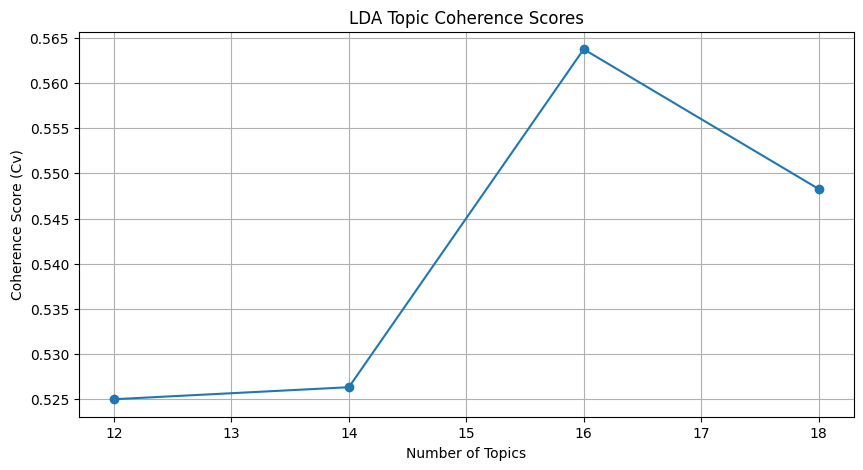

In [35]:
find_optimal_topic_num(processed_2017, range(12, 19, 2))

In [48]:
model, dictionary, corpus = generate_model(processed_2017, 2017, 15)

    # top words per topic
for i, topic in model.show_topics(num_topics=15, num_words=10, formatted=False):
    print(f"Topic {i+1}: {[word for word, _ in topic]}")
    
pyLDAvis.enable_notebook()
vis = pyLDAvis.gensim_models.prepare(model, corpus, dictionary)
pyLDAvis.display(vis)

0.5362587345365106
Topic 1: ['refugee', 'uber', 'parking', 'park', 'transport', 'entering', 'usa', 'bus', 'station', 'veteran']
Topic 2: ['eu', 'brexit', 'independence', 'lord', 'european', 'voting', 'june', 'negotiation', 'voter', 'scottish']
Topic 3: ['insurance', 'loan', 'speed', 'cap', 'motorway', 'point', 'punishment', 'shop', 'street', 'accident']
Topic 4: ['foreign', 'budget', 'military', 'cyclist', 'extra', 'passport', 'space', 'elderly', 'danger', 'share']
Topic 5: ['officer', 'funded', 'experience', 'rail', 'ticket', 'justice', 'selling', 'break', 'professional', 'chance']
Topic 6: ['cat', 'nurse', 'doctor', 'gcse', 'contract', 'large', 'type', 'exam', 'english', 'rest']
Topic 7: ['eu', 'withdrawal', 'welfare', 'pain', 'wale', 'repeal', 'deserve', 'sentience', 'agreement', 'blood']
Topic 8: ['baby', 'cancer', 'mother', 'born', 'bbc', 'disease', 'relationship', 'facility', 'men', 'carers']
Topic 9: ['city', 'charity', 'offered', 'resign', 'customer', 'testing', 'guarantee', 'd

Some topic labels may be:
- Topic 2: Brexit and independence (Scotland/NI)*
- Topic 13: Presidential visits
- Topic 4: Foreign affairs

## Topics for 2018

Num Topics: 12, Cv Coherence Score: 0.5470
Num Topics: 14, Cv Coherence Score: 0.5321
Num Topics: 16, Cv Coherence Score: 0.5345
Num Topics: 18, Cv Coherence Score: 0.5521


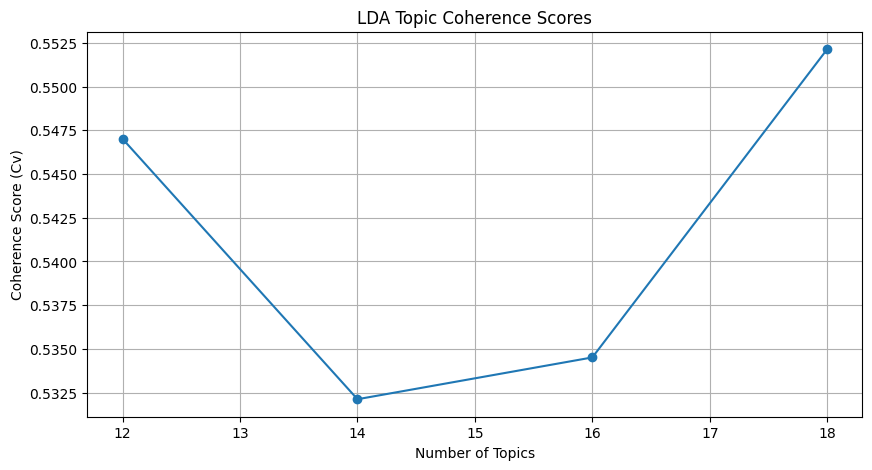

In [36]:
find_optimal_topic_num(processed_2018, range(12, 19, 2))

In [40]:
model, dictionary, corpus = generate_model(processed_2018, 2018, 12)

    # top words per topic
for i, topic in model.show_topics(num_topics=12, num_words=10, formatted=False):
    print(f"Topic {i+1}: {[word for word, _ in topic]}")
    
pyLDAvis.enable_notebook()
vis = pyLDAvis.gensim_models.prepare(model, corpus, dictionary)
pyLDAvis.display(vis)

0.5516358135426286
Topic 1: ['cat', 'syria', 'military', 'air', 'cyclist', 'royal', 'parliamentary', 'weapon', 'fly', 'attack']
Topic 2: ['eu', 'brexit', 'theresa', 'lord', 'northern_ireland', 'confidence', 'democracy', 'electorate', 'democratic', 'voting']
Topic 3: ['plastic', 'foreign', 'water', 'armed', 'waste', 'paper', 'packaging', 'bag', 'veteran', 'meal']
Topic 4: ['universal_credit', 'visit', 'bus', 'point', 'english', 'ticket', 'lane', 'building', 'south', 'daughter']
Topic 5: ['gcse', 'horse', 'exam', 'rent', 'loan', 'tommy_robinson', 'station', 'landlord', 'language', 'basic']
Topic 6: ['knife', 'parking', 'park', 'train', 'fare', 'land', 'shop', 'gang', 'space', 'inquiry']
Topic 7: ['cannabis', 'firework', 'note', 'custom', 'employment', 'release', 'autism', 'infrastructure', 'market', 'entry']
Topic 8: ['bbc', 'tv', 'prison', 'drink', 'justice', 'football', 'passport', 'game', 'news', 'license']
Topic 9: ['insurance', 'hunting', 'sex', 'officer', 'bullying', 'rail', 'scree

Some key topics may be:
- Topic 2: EU and democracy*
- Topic 3: Environment
- Topic 12: Healthcare (carers, maternity, mental health)

## Topics for 2019

Num Topics: 12, Cv Coherence Score: 0.5381
Num Topics: 14, Cv Coherence Score: 0.5198
Num Topics: 16, Cv Coherence Score: 0.5453
Num Topics: 18, Cv Coherence Score: 0.5363


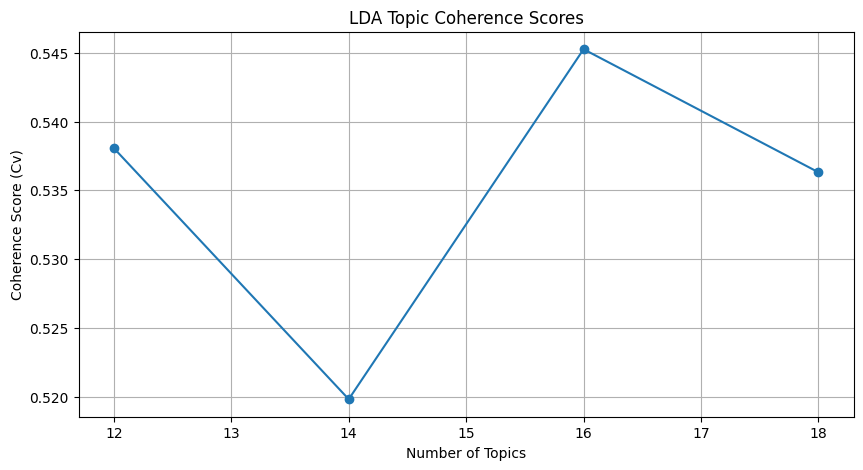

In [37]:
find_optimal_topic_num(processed_2019, range(12, 19, 2))

In [41]:
model, dictionary, corpus = generate_model(processed_2019, 2019, 16)

    # top words per topic
for i, topic in model.show_topics(num_topics=16, num_words=10, formatted=False):
    print(f"Topic {i+1}: {[word for word, _ in topic]}")
    
pyLDAvis.enable_notebook()
vis = pyLDAvis.gensim_models.prepare(model, corpus, dictionary)
pyLDAvis.display(vis)

0.5569883231987403
Topic 1: ['transport', 'water', 'tree', 'emission', 'electric', 'autism', 'expensive', 'supreme', 'game', 'bus']
Topic 2: ['democratic', 'democracy', 'march', 'constituent', 'voter', 'voting', 'represent', 'electorate', 'politician', 'manifesto']
Topic 3: ['shamima_begum', 'isi', 'seat', 'join', 'register', 'candidate', 'convicted', 'visit', 'false', 'lesson']
Topic 4: ['plastic', 'waste', 'recycling', 'advertising', 'packaging', 'inquiry', 'difficult', 'study', 'recyclable', 'resolve']
Topic 5: ['horse', 'parking', 'disease', 'meat', 'pain', 'repeal', 'welfare', 'blood', 'muslim', 'grand']
Topic 6: ['climate', 'plastic', 'population', 'suicide', 'bird', 'specie', 'planet', 'recall', 'natural', 'bag']
Topic 7: ['theresa', 'confidence', 'resign', 'cannabis', 'mandate', 'cancer', 'friend', 'pm', 'maternity', 'accident']
Topic 8: ['brunei', 'sex', 'carers', 'northern_ireland', 'commonwealth', 'leaf', 'gay', 'border', 'smoking', 'ireland']
Topic 9: ['prorogue', 'military

Some key topics may be:
- Topic 2: Democracy and representation*
- Topic 1 and 4: Transport and environment
- Topic 3: International affairs and terrorism

## Topics for 2020

Num Topics: 12, Cv Coherence Score: 0.4899
Num Topics: 14, Cv Coherence Score: 0.4783
Num Topics: 16, Cv Coherence Score: 0.5215
Num Topics: 18, Cv Coherence Score: 0.5072


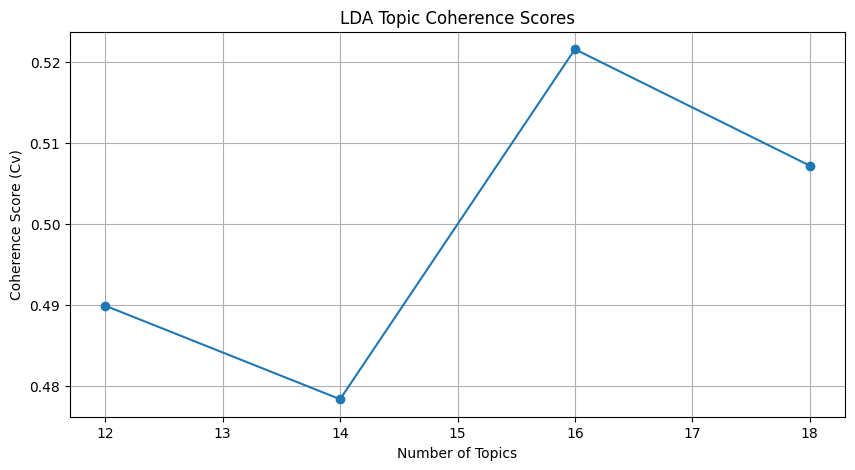

In [38]:
find_optimal_topic_num(processed_2020, range(12, 19, 2))

In [49]:
model, dictionary, corpus = generate_model(processed_2020, 2020, 16)

    # top words per topic
for i, topic in model.show_topics(num_topics=16, num_words=10, formatted=False):
    print(f"Topic {i+1}: {[word for word, _ in topic]}")
    
pyLDAvis.enable_notebook()
vis = pyLDAvis.gensim_models.prepare(model, corpus, dictionary)
pyLDAvis.display(vis)

0.5024871679353107
Topic 1: ['employed', 'salary', 'parking', 'freeze', 'mortgage', 'loan', 'rent', 'employee', 'relief', 'building']
Topic 2: ['testing', 'baby', 'inquiry', 'awareness', 'cat', 'procedure', 'homeless', 'contract', 'mother', 'minister']
Topic 3: ['lesson', 'partner', 'election', 'prisoner', 'prison', 'release', 'penalty', 'kid', 'tougher', 'environmental']
Topic 4: ['vaccine', 'vaccination', 'zoo', 'ppe', 'vat', 'priority', 'reverse', 'real', 'break', 'reduction']
Topic 5: ['wedding', 'foreign', 'transport', 'covering', 'flight', 'north', 'send', 'sexual', 'lift', 'south']
Topic 6: ['eu', 'brexit', 'speed', 'maternity', 'immigrant', 'transition', 'publish', 'agreement', 'traffic', 'accident']
Topic 7: ['nurse', 'tuition', 'international', 'accommodation', 'refund', 'loan', 'reimburse', 'registration', 'teaching', 'nursing']
Topic 8: ['statue', 'citizenship', 'drug', 'childcare', 'application', 'exempt', 'early', 'monument', 'setting', 'nursery']
Topic 9: ['plastic', 'bb

Some key topics may be:
- Topic 12: Exams and education
- Topic 1: Work and pay*
- Topic 16: Frontline healthcare

## Topics for 2021

Num Topics: 10, Cv Coherence Score: 0.5537
Num Topics: 13, Cv Coherence Score: 0.5472
Num Topics: 16, Cv Coherence Score: 0.5740
Num Topics: 19, Cv Coherence Score: 0.5570
Num Topics: 22, Cv Coherence Score: 0.5448


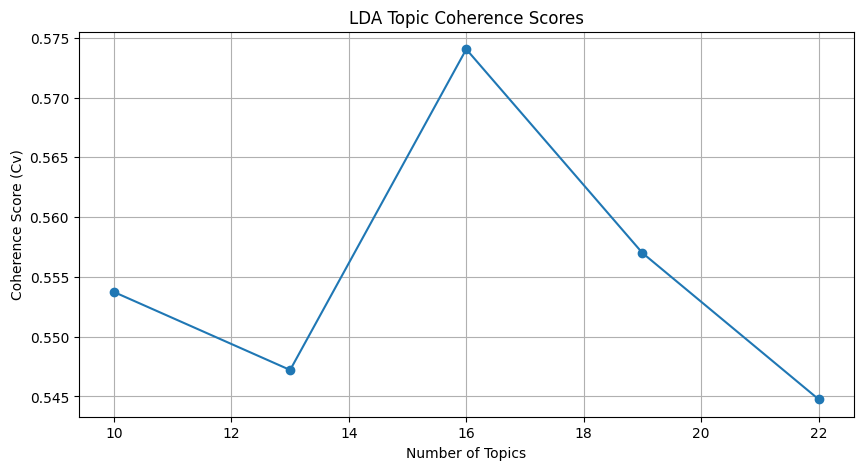

In [43]:
find_optimal_topic_num(processed_2021, topic_range)

In [50]:
model, dictionary, corpus = generate_model(processed_2021, 2021, 16)

    # top words per topic
for i, topic in model.show_topics(num_topics=16, num_words=10, formatted=False):
    print(f"Topic {i+1}: {[word for word, _ in topic]}")
    
pyLDAvis.enable_notebook()
vis = pyLDAvis.gensim_models.prepare(model, corpus, dictionary)
pyLDAvis.display(vis)

0.5764561331224484
Topic 1: ['plastic', 'baby', 'waste', 'council', 'packaging', 'environmental', 'foreign', 'label', 'registered', 'contact']
Topic 2: ['accommodation', 'religious', 'racism', 'hate', 'gender', 'reduction', 'traffic', 'sold', 'tuition', 'surgery']
Topic 3: ['firework', 'nurse', 'june', 'green', 'insurance', 'annual', 'st', 'import', 'citizenship', 'wedding']
Topic 4: ['parking', 'park', 'election', 'send', 'voting', 'defence', 'city', 'household', 'uniform', 'awareness']
Topic 5: ['license', 'protest', 'domestic', 'welfare', 'sentencing', 'landlord', 'sell', 'building', 'specie', 'vet']
Topic 6: ['exam', 'gcse', 'cancel', 'grade', 'college', 'consent', 'summer', 'user', 'bbc', 'account']
Topic 7: ['water', 'specific', 'cannabis', 'fishing', 'land', 'net', 'climate', 'drug', 'street', 'hospitality']
Topic 8: ['penalty', 'contract', 'salary', 'employer', 'theft', 'convicted', 'history', 'kit', 'buyer', 'walking']
Topic 9: ['eu', 'vat', 'rape', 'carers', 'sexual', 'agreem

Some key topics:
- Topic 13: Vaccinations*
- Topic 16: Quarantine
- Topic 6: Exams and GCSEs (Education)

## Topics for 2022

Num Topics: 10, Cv Coherence Score: 0.5843
Num Topics: 13, Cv Coherence Score: 0.6097
Num Topics: 16, Cv Coherence Score: 0.6135
Num Topics: 19, Cv Coherence Score: 0.6012
Num Topics: 22, Cv Coherence Score: 0.6025


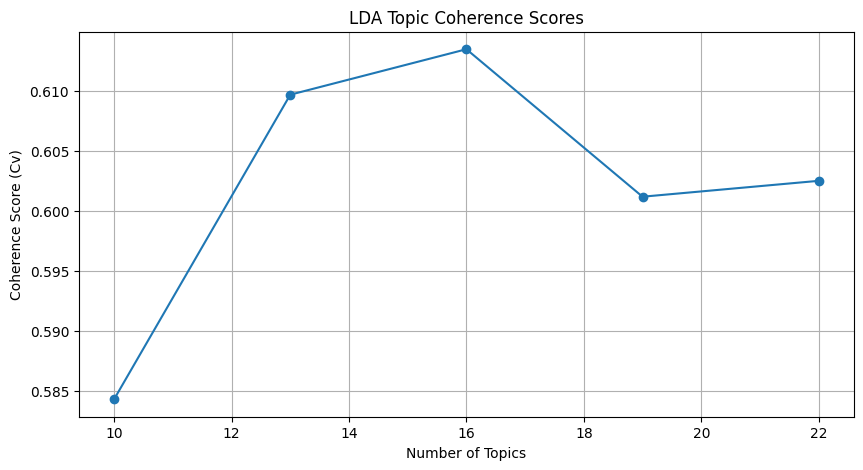

In [44]:
find_optimal_topic_num(processed_2022, topic_range)

In [27]:
model, dictionary, corpus = generate_model(processed_2022, 2022, 19)

    # top words per topic
for i, topic in model.show_topics(num_topics=19, num_words=10, formatted=False):
    print(f"Topic {i+1}: {[word for word, _ in topic]}")
    
pyLDAvis.enable_notebook()
vis = pyLDAvis.gensim_models.prepare(model, corpus, dictionary)
pyLDAvis.display(vis)

0.6024539781936576
Topic 1: ['energy', 'cap', 'profit', 'bill', 'statutory', 'tenant', 'welfare', 'license', 'land', 'step']
Topic 2: ['allowance', 'household', 'exam', 'old', 'legalise', 'activity', 'treated', 'justice', 'st', 'content']
Topic 3: ['damage', 'english', 'card', 'early', 'causing', 'extra', 'language', 'gcse', 'subject', 'wear']
Topic 4: ['parking', 'disabled', 'childcare', 'international', 'drug', 'behaviour', 'charity', 'loss', 'registered', 'match']
Topic 5: ['ukraine', 'ukrainian', 'russian', 'refugee', 'russia', 'cyclist', 'war', 'military', 'asylum', 'enter']
Topic 6: ['inquiry', 'baby', 'nurse', 'minister', 'mother', 'salary', 'conduct', 'birth', 'role', 'suspend']
Topic 7: ['centre', 'air', 'publish', 'park', 'announced', 'facility', 'waste', 'matter', 'target', 'suicide']
Topic 8: ['cat', 'domestic', 'equality', 'gender', 'penalty', 'reverse', 'convicted', 'employee', 'vaccination', 'shop']
Topic 9: ['vat', 'sex', 'basic', 'assessment', 'display', 'aged', 'physi

Some key topics:
- Topic 14: Fuel, gas and energy supplies
- Topic 1: Energy caps
- Topic 5: Ukraine and Russia
- Topic 6: Loans and debt
- Topic 8: Gender and sex, animal safety*
- Topic 4: Childcare and care for vulnerable people (disability, NHS, those going through grief and loss)*
- Topic 6: NHS and healthcare admin*

## Topics for 2023

Num Topics: 10, Cv Coherence Score: 0.6221
Num Topics: 13, Cv Coherence Score: 0.6407
Num Topics: 16, Cv Coherence Score: 0.6131
Num Topics: 19, Cv Coherence Score: 0.6124
Num Topics: 22, Cv Coherence Score: 0.6003


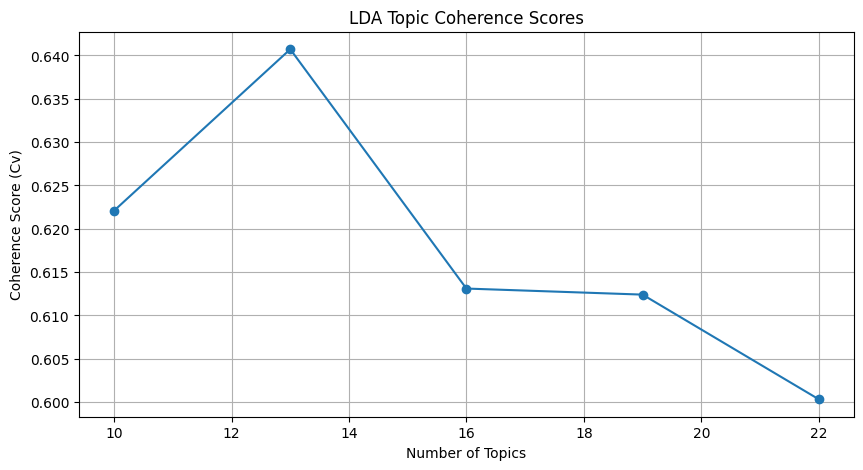

In [45]:
find_optimal_topic_num(processed_2023, topic_range)

In [37]:
model, dictionary, corpus = generate_model(processed_2023, 2023, 21)

    # top words per topic
for i, topic in model.show_topics(num_topics=21, num_words=10, formatted=False):
    print(f"Topic {i+1}: {[word for word, _ in topic]}")
    
pyLDAvis.enable_notebook()
vis = pyLDAvis.gensim_models.prepare(model, corpus, dictionary)
pyLDAvis.display(vis)

0.6194399154660979
Topic 1: ['secondary', 'seek', 'send', 'centre', 'asylum', 'sport', 'healthcare', 'concerned', 'funded', 'facility']
Topic 2: ['election', 'knife', 'cigarette', 'greater', 'check', 'damage', 'weapon', 'created', 'mandate', 'attack']
Topic 3: ['gcse', 'allowance', 'scrap', 'conduct', 'exam', 'outdated', 'higher', 'trained', 'release', 'population']
Topic 4: ['wale', 'maintenance', 'israel', 'old', 'multiple', 'drive', 'welsh', 'maximum', 'loss', 'buy']
Topic 5: ['sexual', 'meet', 'primary', 'traffic', 'alcohol', 'development', 'partner', 'building', 'point', 'matter']
Topic 6: ['assessment', 'universal_credit', 'plastic', 'claimant', 'autism', 'climate', 'packaging', 'contribution', 'purchase', 'award']
Topic 7: ['train', 'awareness', 'officer', 'don', 'carers', 'freedom', 'afford', 'starting', 'paper', 'concern']
Topic 8: ['toilet', 'drug', 'cat', 'station', 'minister', 'project', 'convicted', 'immigration', 'venue', 'suffer']
Topic 9: ['penalty', 'threshold', 'speed

Some key topics:
- Topic 10: Disabilities
- Topic 6: Universal credit
- Topic 11: Crime and sexual offences
- Topic 19: Misc*
- Topic 20: Misc (Gender, animal care, energy)*
- Topic 17: Energy, land, childcare*

## Topics for 2024

Num Topics: 10, Cv Coherence Score: 0.6335
Num Topics: 13, Cv Coherence Score: 0.6044
Num Topics: 16, Cv Coherence Score: 0.6037
Num Topics: 19, Cv Coherence Score: 0.5708
Num Topics: 22, Cv Coherence Score: 0.5492


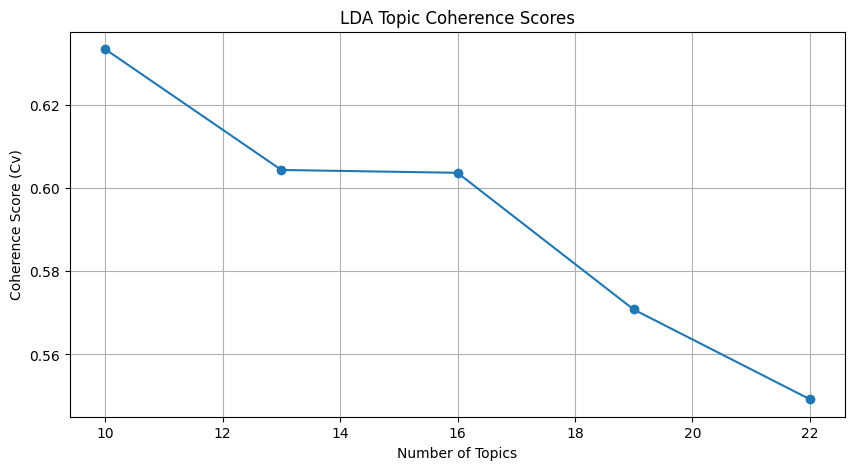

In [46]:
find_optimal_topic_num(processed_2024, topic_range)

In [32]:
model, dictionary, corpus = generate_model(processed_2024, 2024, 19)

    # top words per topic
for i, topic in model.show_topics(num_topics=19, num_words=10, formatted=False):
    print(f"Topic {i+1}: {[word for word, _ in topic]}")
    
pyLDAvis.enable_notebook()
vis = pyLDAvis.gensim_models.prepare(model, corpus, dictionary)
pyLDAvis.display(vis)

0.5696752479748148
Topic 1: ['healthcare', 'equality', 'primary', 'professional', 'parking', 'waiting', 'changing', 'enforcement', 'seek', 'international']
Topic 2: ['insurance', 'youth', 'military', 'water', 'taxpayer', 'organisation', 'matter', 'customer', 'war', 'add']
Topic 3: ['budget', 'gender', 'trust', 'ilr', 'security', 'war', 'employment', 'cross', 'spent', 'add']
Topic 4: ['energy', 'transport', 'defence', 'break', 'reverse', 'farm', 'disability', 'identity', 'transparency', 'quality']
Topic 5: ['amend', 'registered', 'rent', 'considered', 'calling', 'landlord', 'bus', 'tenant', 'specific', 'role']
Topic 6: ['allowance', 'knife', 'site', 'experience', 'eligible', 'ability', 'loss', 'veteran', 'serving', 'crucial']
Topic 7: ['profit', 'status', 'voting', 'recognise', 'build', 'immigration', 'household', 'buy', 'pressure', 'injury']
Topic 8: ['prescription', 'address', 'scrap', 'easier', 'convicted', 'afford', 'concerned', 'basic', 'effect', 'propose']
Topic 9: ['election', 'd

Distinct topics are harder to recognise for 2024. Some key topics may be:
- Topic 7: Welfare*
- Topic 4: Energy and tax
- Topic 9: Election and immigration*
- Topic 6: Allowance, knife, site*

## Topics for 2025

Num Topics: 10, Cv Coherence Score: 0.5093
Num Topics: 13, Cv Coherence Score: 0.5253
Num Topics: 16, Cv Coherence Score: 0.5389
Num Topics: 19, Cv Coherence Score: 0.5603
Num Topics: 22, Cv Coherence Score: 0.5614


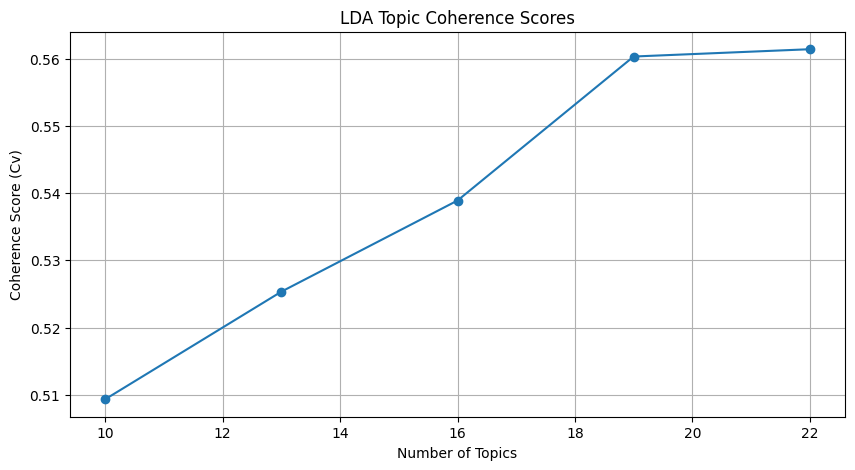

In [47]:
find_optimal_topic_num(processed_2025, topic_range)

In [30]:
model, dictionary, corpus = generate_model(processed_2025, 2025, 17)

    # top words per topic
for i, topic in model.show_topics(num_topics=17, num_words=10, formatted=False):
    print(f"Topic {i+1}: {[word for word, _ in topic]}")
    
pyLDAvis.enable_notebook()
vis = pyLDAvis.gensim_models.prepare(model, corpus, dictionary)
pyLDAvis.display(vis)

0.5444197665021534
Topic 1: ['parking', 'statutory', 'economic', 'emotional', 'proposed', 'park', 'settlement', 'enforcement', 'policy', 'requiring']
Topic 2: ['security', 'address', 'gender', 'role', 'vital', 'shop', 'domestic', 'greater', 'responsible', 'policy']
Topic 3: ['ukraine', 'policy', 'accountable', 'park', 'responsible', 'responsibility', 'insurance', 'provider', 'parking', 'council']
Topic 4: ['loss', 'allowance', 'funded', 'labour', 'contribution', 'insurance', 'vital', 'accountability', 'transparency', 'responsible']
Topic 5: ['inquiry', 'grooming_gang', 'military', 'international', 'requiring', 'establish', 'failure', 'proposed', 'justice', 'girl']
Topic 6: ['build', 'legislate', 'provider', 'sex', 'settlement', 'domestic', 'specific', 'accountable', 'secondary', 'existing']
Topic 7: ['activity', 'election', 'eu', 'insurance', 'drive', 'enforcement', 'vital', 'ensuring', 'reverse', 'proposed']
Topic 8: ['penalty', 'amend', 'employer', 'enforce', 'justice', 'strengthen',

Some key topics:
- Topic 10: Migration and welfare
- Topic 14: Disability and crime
- Topic 11: Gender and misc*
- Topic 17: ilr, domestic, knife*
- Topic 1: parking statutory, economic*